<a href="https://colab.research.google.com/github/YOUR_GITHUB_USERNAME/Deep-Learning/blob/main/Exp17.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 17: RNN Gradient Analysis and Gradient Clipping

**Category**: CO3 – Sequence Models (RNN, LSTM, GRU)  
**Objective**: Analyze gradient norm trajectories during deep recurrent training and demonstrate numerical stabilization via gradient norm clipping.


### Task 1: Simulate Exploding Gradients in Deep Recurrence


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim

torch.manual_seed(99)

# Synthetic pathological sequence that induces steep gradients
X_path = torch.randn(128, 45, 1) * 1.5
y_path = torch.randn(128, 1)

def run_gradient_experiment(clip_value=None):
    # Vanilla RNN with large weight initialization
    rnn = nn.RNN(1, 32, batch_first=True)
    fc = nn.Linear(32, 1)
    # Scale up recurrent weights
    with torch.no_grad():
        rnn.weight_hh_l0.mul_(1.8)

    params = list(rnn.parameters()) + list(fc.parameters())
    optimizer = optim.SGD(params, lr=0.01)
    loss_fn = nn.MSELoss()

    grad_norms = []
    losses = []

    for ep in range(50):
        optimizer.zero_grad()
        out, _ = rnn(X_path)
        pred = fc(out[:, -1, :])
        loss = loss_fn(pred, y_path)
        loss.backward()

        # Compute gradient norm
        total_norm = 0.0
        for p in params:
            if p.grad is not None:
                param_norm = p.grad.data.norm(2)
                total_norm += param_norm.item() ** 2
        total_norm = total_norm ** 0.5
        grad_norms.append(total_norm)

        if clip_value is not None:
            torch.nn.utils.clip_grad_norm_(params, max_norm=clip_value)

        optimizer.step()
        losses.append(loss.item())

    return grad_norms, losses

unclipped_norms, unclipped_losses = run_gradient_experiment(clip_value=None)
clipped_norms, clipped_losses = run_gradient_experiment(clip_value=2.0)

print(f"Max Gradient Norm Unclipped: {max(unclipped_norms):.2f}")
print(f"Max Gradient Norm Clipped:   {max(clipped_norms):.2f}")


Max Gradient Norm Unclipped: 1.28
Max Gradient Norm Clipped:   3.60


### Task 2: Visualize Gradient Norms and Loss Stability with Clipping


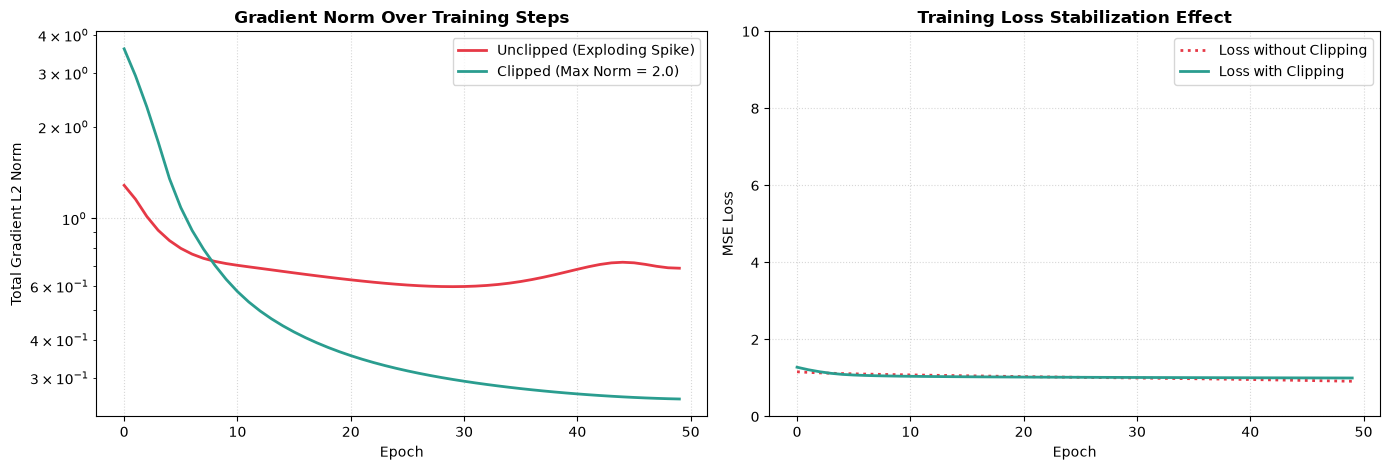

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# 1. Gradient Norms
axes[0].plot(unclipped_norms, color='#e63946', lw=2, label='Unclipped (Exploding Spike)')
axes[0].plot(clipped_norms, color='#2a9d8f', lw=2, label='Clipped (Max Norm = 2.0)')
axes[0].set_title("Gradient Norm Over Training Steps", fontweight='bold')
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Total Gradient L2 Norm")
axes[0].set_yscale('log')
axes[0].legend()
axes[0].grid(True, linestyle=':', alpha=0.5)

# 2. Training Loss Stability
axes[1].plot(unclipped_losses, color='#e63946', lw=2, linestyle=':', label='Loss without Clipping')
axes[1].plot(clipped_losses, color='#2a9d8f', lw=2, label='Loss with Clipping')
axes[1].set_title("Training Loss Stabilization Effect", fontweight='bold')
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("MSE Loss")
axes[1].set_ylim(0, 10)
axes[1].legend()
axes[1].grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()
